# 06 · Open-system dynamics: T1 and T2 with the Lindblad master equation (QuTiP)

A real qubit isn't isolated. It leaks energy to and picks up random phase from its environment.
A state vector can't describe that, so we use a **density matrix**:
$$\rho = \begin{pmatrix} \rho_{00} & \rho_{01} \\ \rho_{10} & \rho_{11}\end{pmatrix}$$
The diagonal entries are the **populations** (probabilities of 0 and 1). The off-diagonal entries are the
**coherences**: the "quantumness" that makes interference possible.

The **Lindblad master equation** is the standard model for a memoryless (Markovian) environment:
$$\dot\rho = -i[H,\rho] + \sum_k \Big(L_k\rho L_k^\dagger - \tfrac12\{L_k^\dagger L_k,\rho\}\Big)$$

| Process | Collapse operator $L_k$ | Effect |
|---|---|---|
| **Energy relaxation (T1)** | $\sqrt{1/T_1}\;\sigma_-$, with $\sigma_- = |0\rangle\langle1|$ | $|1\rangle$ decays to $|0\rangle$: $\rho_{11} \propto e^{-t/T_1}$ |
| **Pure dephasing** | $\sqrt{\gamma_\phi/2}\;\sigma_z$ | phases randomise; populations unchanged |

Coherence decays at the total rate $1/T_2 = 1/(2T_1) + \gamma_\phi$. Relaxation contributes too,
which is why physics requires $T_2 \le 2T_1$.

We use typical superconducting-qubit numbers in **microseconds**: $T_1 = 50\,\mu s$, $T_2 = 30\,\mu s$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from scipy.optimize import curve_fit

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed series order: blue, orange, aqua

# Explicit basis so the convention is unambiguous: |0> = ground, |1> = excited
g, e = qt.basis(2, 0), qt.basis(2, 1)
sm = g * e.dag()                               # sigma_-  = |0><1| : lowers |1> -> |0>
X = g * e.dag() + e * g.dag()                  # Pauli X
Y = -1j * g * e.dag() + 1j * e * g.dag()       # Pauli Y
Z = g * g.dag() - e * e.dag()                  # Pauli Z (+1 for |0>)
P1 = e * e.dag()                               # projector onto |1>: <P1> = rho_11

T1, T2 = 50.0, 30.0                            # microseconds
assert T2 <= 2 * T1, "unphysical: T2 cannot exceed 2*T1"
gamma1 = 1 / T1
gamma_phi = 1 / T2 - 1 / (2 * T1)              # extra (pure) dephasing on top of what T1 causes

c_ops = [
    np.sqrt(gamma1) * sm,                      # amplitude damping (T1)
    np.sqrt(gamma_phi / 2) * Z,                # pure dephasing: decays rho_01 at rate gamma_phi
]
tlist = np.linspace(0, 150, 301)               # 0..150 us
H0 = 0 * Z                                     # rotating frame, on resonance: no coherent rotation

def style(ax, xlabel="time (µs)", ylabel=""):
    ax.set(xlabel=xlabel, ylabel=ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9")

## 1. T1: start in $|1\rangle$ and watch the population decay

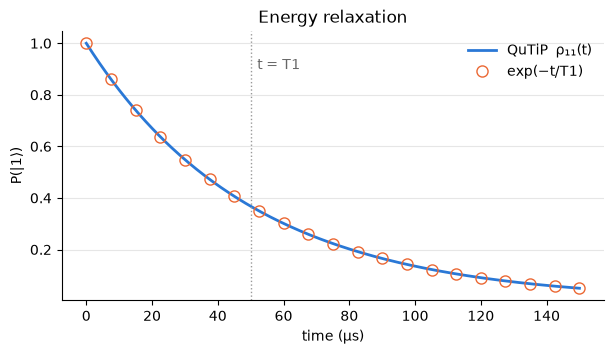

In [2]:
res_t1 = qt.mesolve(H0, e * e.dag(), tlist, c_ops, e_ops=[P1])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tlist, res_t1.expect[0], color=COLORS[0], lw=2, label="QuTiP  ρ₁₁(t)")
ax.plot(tlist[::15], np.exp(-tlist[::15] / T1), "o", color=COLORS[1], ms=8, mfc="none", label="exp(−t/T1)")
ax.axvline(T1, color="0.6", ls=":", lw=1); ax.text(T1 + 2, 0.9, "t = T1", color="0.4")
style(ax, ylabel="P(|1⟩)"); ax.legend(frameon=False); ax.set_title("Energy relaxation")
plt.show()

## 2. T2: start in $|+\rangle = (|0\rangle+|1\rangle)/\sqrt2$ and watch the coherence decay
$|\rho_{01}| = \tfrac12\sqrt{\langle X\rangle^2 + \langle Y\rangle^2}$ starts at 0.5 and decays as $e^{-t/T_2}$.
Meanwhile the population relaxes on the *slower* T1 timescale, ending up all in $|0\rangle$.

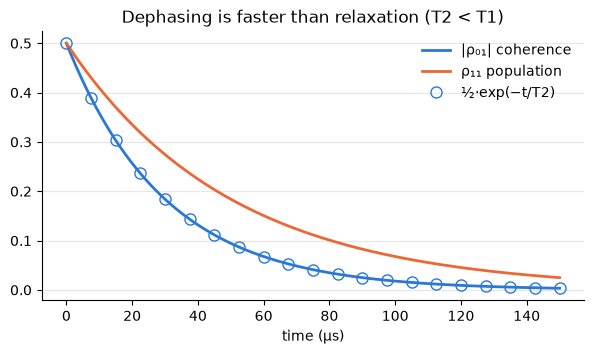

rho(t = 0 us) =
[[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]

rho(t = 30 us) =
[[0.726+0.j 0.184+0.j]
 [0.184+0.j 0.274+0.j]]

rho(t = 150 us) =
[[0.975+0.j 0.003+0.j]
 [0.003+0.j 0.025+0.j]]



In [3]:
plus = (g + e).unit()
res_t2 = qt.mesolve(H0, qt.ket2dm(plus), tlist, c_ops, e_ops=[X, Y, P1], options={"store_states": True})
ex, ey, p1 = res_t2.expect
coherence = 0.5 * np.sqrt(np.real(ex) ** 2 + np.real(ey) ** 2)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tlist, coherence, color=COLORS[0], lw=2, label="|ρ₀₁| coherence")
ax.plot(tlist, np.real(p1), color=COLORS[1], lw=2, label="ρ₁₁ population")
ax.plot(tlist[::15], 0.5 * np.exp(-tlist[::15] / T2), "o", color=COLORS[0], ms=8, mfc="none", label="½·exp(−t/T2)")
style(ax); ax.legend(frameon=False); ax.set_title("Dephasing is faster than relaxation (T2 < T1)")
plt.show()

for t_show in [0, 30, 150]:
    i = np.argmin(abs(tlist - t_show))
    print(f"rho(t = {tlist[i]:.0f} us) =\n{np.round(res_t2.states[i].full(), 3)}\n")

Read the printed matrices like this. At $t=0$ every entry is 0.5, so the state is fully coherent. At 30 µs the
off-diagonals have shrunk by $e^{-1}$. At 150 µs the qubit is almost entirely $|0\rangle$ with essentially no
coherence left: it has become a **classical** state.

## 3. Ramsey experiment: how T2 is measured in a lab
Add a small detuning $\Delta$ (the drive frequency slightly off the qubit frequency). The Bloch vector
then precesses around z while it shrinks, and $\langle X\rangle$ shows **decaying fringes**. Fitting the
envelope recovers T2.

fitted T2 = 30.0 us   (true 30.0 us),  fringe frequency = 50.0 kHz


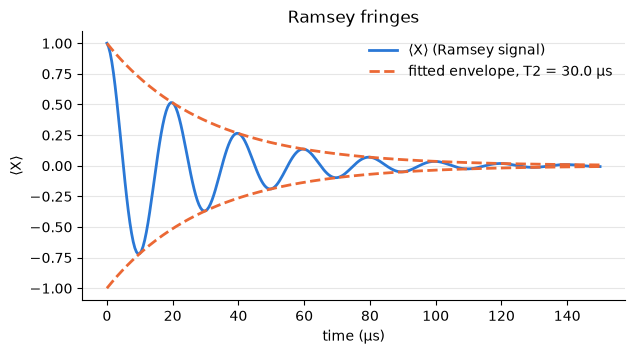

In [4]:
delta = 2 * np.pi * 0.05                      # rad/us -> 50 kHz detuning, 20 us fringe period
H_ramsey = 0.5 * delta * Z
res_r = qt.mesolve(H_ramsey, qt.ket2dm(plus), tlist, c_ops, e_ops=[X, Y, Z])
rx, ry, rz = (np.real(v) for v in res_r.expect)

model = lambda t, A, T, f, ph: A * np.exp(-t / T) * np.cos(2 * np.pi * f * t + ph)
(A, T_fit, f_fit, ph), _ = curve_fit(model, tlist, rx, p0=[1, 20, 0.05, 0])
print(f"fitted T2 = {T_fit:.1f} us   (true {T2} us),  fringe frequency = {f_fit * 1e3:.1f} kHz")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tlist, rx, color=COLORS[0], lw=2, label="⟨X⟩ (Ramsey signal)")
ax.plot(tlist, abs(A) * np.exp(-tlist / T_fit), color=COLORS[1], lw=2, ls="--", label=f"fitted envelope, T2 = {T_fit:.1f} µs")
ax.plot(tlist, -abs(A) * np.exp(-tlist / T_fit), color=COLORS[1], lw=2, ls="--")
style(ax, ylabel="⟨X⟩"); ax.legend(frameon=False); ax.set_title("Ramsey fringes")
plt.show()

## 4. The same trajectory on the Bloch sphere
The Bloch vector spirals inward (dephasing) and drifts towards the north pole, $|0\rangle$ (relaxation). The pure states are on the surface and the mixed states are inside.

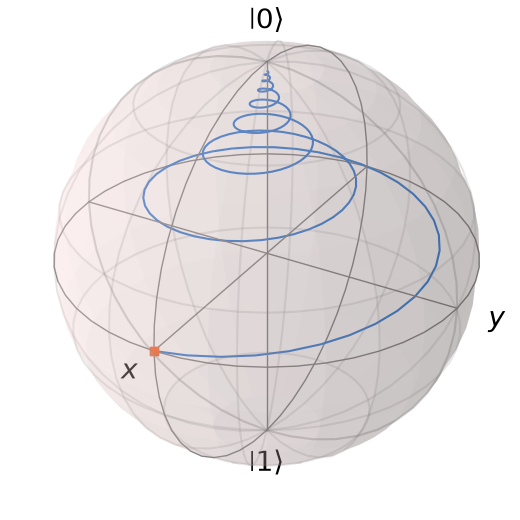

In [5]:
b = qt.Bloch()
b.add_points([rx, ry, rz], meth="l", colors=[COLORS[0]])         # 'l' = draw as a line
b.add_points([rx[0], ry[0], rz[0]], colors=[COLORS[1]])          # start point, |+>
b.show()

**Try it:**
* Set `gamma_phi = 0` (so $T_2 = 2T_1$, the T1 limit) and compare.
* Start in $|1\rangle$ in the Ramsey experiment. You get no fringes, because there's no coherence to begin with.
* Make $T_2$ very short and watch the spiral collapse onto the z axis.